# Supplementary Figure S8b. Distance to the nearest TSS of *cis*-only, *trans*-only and *cis*-*trans* loci

For each colocalized locus, the signed distance (strand-aware, kb) from the credible-set variant closest to any protein-coding TSS to that TSS. Distances within ±100 kb are binned into 10-kb bins; each curve shows the proportion of loci per bin, normalized within each group **over loci within ±100 kb** (cis-only 10,628 of 11,412; trans-only 25,456 of 45,407; cis-trans 3,765 of 4,023 loci). Groups use the main-Figure-3a filtered loci with *trans*-eGene and *trans*-eProgram combined (*trans*-only loci therefore all colocalize with a biomarker-QTL). No statistical test is involved.

Input: `data/Figure_S8b_tss_distance_binned.rds`.

In [1]:
library(ggplot2)
s8b <- readRDS("data/Figure_S8b_tss_distance_binned.rds")
head(s8b)
unique(s8b[, c("category", "n_loci_total", "n_loci_within_100kb")])

,category,bin_center_kb,n_loci,proportion,n_loci_total,n_loci_within_100kb
,<fct>,<dbl>,<int>,<dbl>,<int>,<int>
1,cis-only,-95,40,0.003763643,11412,10628
2,cis-only,-85,51,0.004798645,11412,10628
3,cis-only,-75,54,0.005080918,11412,10628
4,cis-only,-65,81,0.007621377,11412,10628
5,cis-only,-55,78,0.007339104,11412,10628
6,cis-only,-45,140,0.013172751,11412,10628


,category,n_loci_total,n_loci_within_100kb
,<fct>,<int>,<int>
1,cis-only,11412,10628
21,trans-only,45407,25456
41,cis-trans,4023,3765


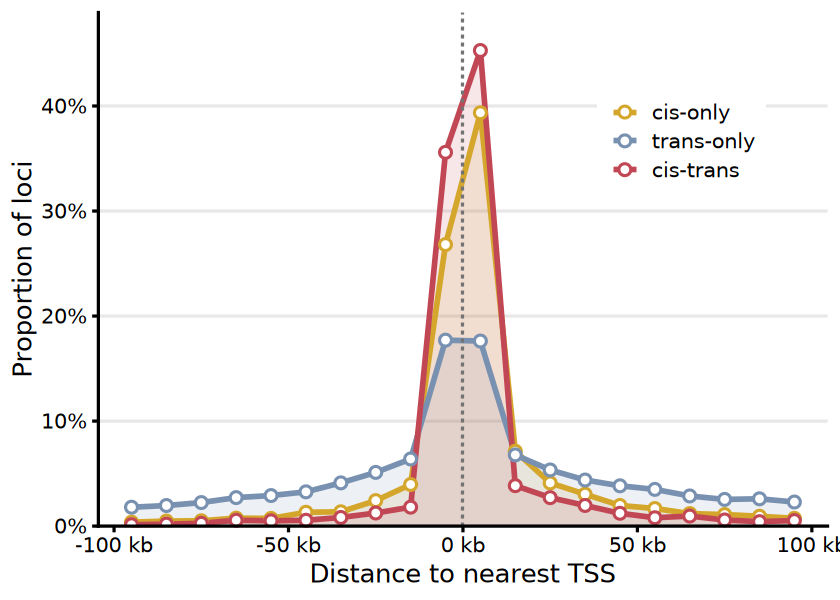

In [2]:
cols <- c("cis-only" = "#D4A72C", "trans-only" = "#7991B1", "cis-trans" = "#C24755")
s8b$category <- factor(s8b$category, levels = names(cols))

p <- ggplot(s8b, aes(x = bin_center_kb, y = proportion, color = category, fill = category)) +
  geom_ribbon(aes(ymin = 0, ymax = proportion), alpha = 0.13, color = NA) +
  geom_line(linewidth = 1.2) +
  geom_point(size = 2.4, shape = 21, fill = "white", stroke = 1) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "grey45") +
  scale_color_manual(values = cols, name = NULL) +
  scale_fill_manual(values = cols, guide = "none") +
  scale_x_continuous(breaks = seq(-100, 100, 50), labels = function(x) paste0(x, " kb")) +
  scale_y_continuous(labels = function(x) paste0(100 * x, "%"), expand = expansion(mult = c(0, 0.08))) +
  labs(x = "Distance to nearest TSS", y = "Proportion of loci") +
  theme_classic(base_size = 15) +
  theme(legend.position = c(0.8, 0.75), panel.grid.major.y = element_line(color = "grey91"))

options(repr.plot.width = 7, repr.plot.height = 5)
p